In [71]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
from PIL import Image


In [72]:
image_paths = [f"images/{i}.jpg" for i in range(1, 10)]

In [75]:
def crop_square(img):
    w, h = img.size
    size = min(w, h)
    left = (w - size) // 2
    top = (h - size) // 2
    return img.crop((left, top, left + size, top + size))

def edit(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)

    # hsv[:, :, 0] *= 1.3
    # hsv[:, :, 0] = np.clip(hsv[:, :, 0], 0, 255)

    hsv[:, :, 1] *= 1.1
    hsv[:, :, 1] = np.clip(hsv[:, :, 1], 0, 255)
    img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)


    return img
    

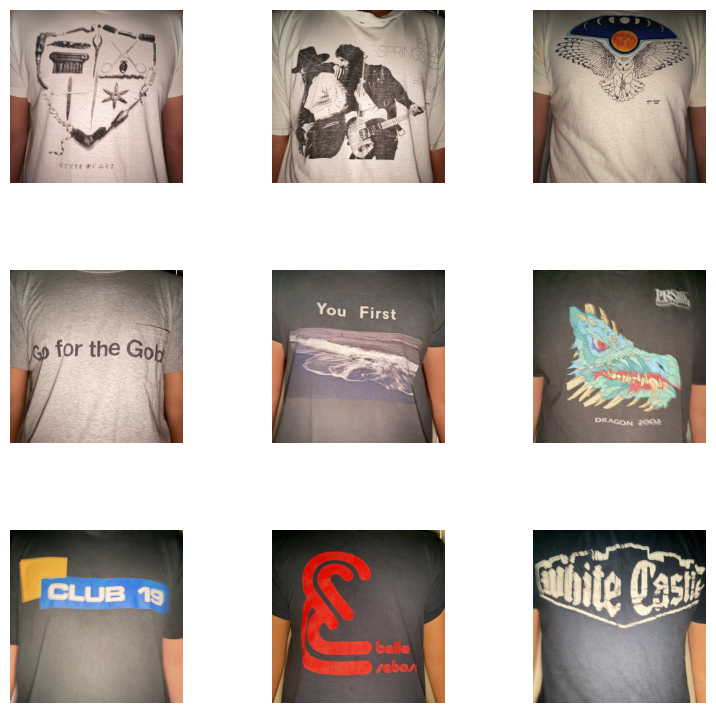

In [ ]:
fig, axes = plt.subplots(
    3, 3,
    figsize=(9, 9),
    gridspec_kw={"wspace": .1, "hspace": .1}
)

for ax, path in zip(axes.flat, image_paths):
    img = Image.open(path).convert("RGB")
    img = crop_square(img).rotate(270)

    img = np.array(img)
    img = edit(img)

    ax.imshow(img)
    ax.axis("off")

plt.subplots_adjust(wspace=0, hspace=0)
plt.show()